In [30]:
import jax.numpy as jnp
import seaborn as sns
import matplotlib.pyplot as plt
import jax.random as random
import pandas as pd
from sklearn.linear_model import LinearRegression

In [8]:
pnrg_key = random.PRNGKey(seed=123)


In [40]:
x = jnp.arange(0, 120, 1)
y = jnp.sin(x * 0.1) + jnp.cos(x * 0.1) + random.normal(pnrg_key, shape=(120,)) * 0.1 + jnp.linspace(0, 1, 120) + 0.5

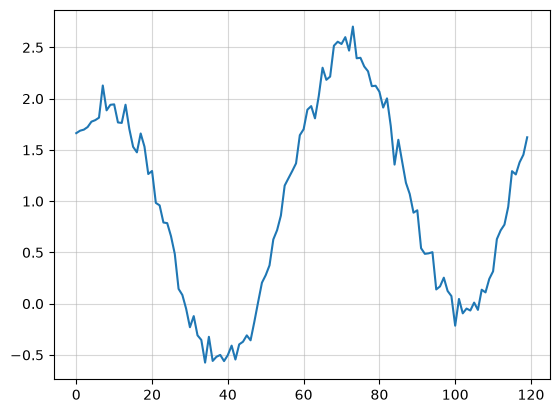

In [41]:
fig, ax = plt.subplots()
ax.plot(x, y)
ax.grid(alpha=0.5)

In [42]:
df = pd.DataFrame({'x': x, 'y': y})
df['lag_1'] = df['y'].shift(1)
df

,x,y,lag_1
0,0,1.663595,NaN
1,1,1.687322,1.663595
2,2,1.697755,1.687322
3,3,1.723139,1.697755
4,4,1.775428,1.723139
...,...,...,...
115,115,1.292795,0.945423
116,116,1.260772,1.292795
117,117,1.378895,1.260772
118,118,1.453158,1.378895


In [51]:
X = df.loc[:, ['x', 'lag_1']].dropna()
y = df.loc[:, 'y'].align(X, join='inner')[0]

In [52]:
model = LinearRegression()
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0. ,0.99]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x','lag_1']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-0.01879
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [53]:
y_pred = pd.Series(model.predict(X), index=X.index)

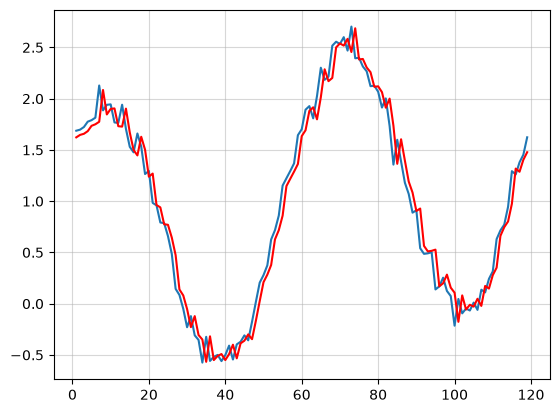

In [54]:
ax = y.plot()
y_pred.plot(ax=ax, color='red')
ax.grid(True, alpha=0.5)

So, using the lag (`shift(1)`) and time based features, we are able to model a time series using linear regression.

**Next**: How do I compare two different models?